# Практическая работа: Реализация логистической регрессии с нуля

**Цель работы:** Написать собственный класс логистической регрессии для решения задачи бинарной классификации с использованием градиентного спуска. Реализовать функции для вычисления метрик качества классификации (Accuracy, Precision, Recall, F1-Score).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Реализация класса логистической регрессии

In [7]:
class MyLogisticRegression:
    def __init__(self, learning_rate=0.1, n_iters=1000, threshold=0.5):
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.threshold = threshold
        self.weights = None
        self.loss_history = []
        
    def _add_intercept(self, X):
        intercept = np.ones((X.shape[0], 1))
        return np.concatenate((intercept, X), axis=1)
    
    def _sigmoid(self, z):
        # Ограничиваем z для избежания переполнения (overflow) в exp
        z = np.clip(z, -250, 250)
        return 1 / (1 + np.exp(-z))
        
    def fit(self, X, y):
        X_ext = self._add_intercept(X)
        n_samples, n_features = X_ext.shape
        
        self.weights = np.zeros(n_features)
        
        for i in range(self.n_iters):
            linear_model = X_ext @ self.weights
            predictions = self._sigmoid(linear_model)
            
            gradient = (1 / n_samples) * (X_ext.T @ (predictions - y))
            
            self.weights -= self.learning_rate * gradient
            
            eps = 1e-15
            predictions = np.clip(predictions, eps, 1 - eps)
            loss = -np.mean(y * np.log(predictions) + (1 - y) * np.log(1 - predictions))
            self.loss_history.append(loss)
            
    def predict_proba(self, X):
        X_ext = self._add_intercept(X)
        return self._sigmoid(X_ext @ self.weights)
    
    def predict(self, X):
        probas = self.predict_proba(X)
        return (probas >= self.threshold).astype(int)
    
    @staticmethod
    def accuracy(y_true, y_pred):
        return np.mean(y_true == y_pred)
    
    @staticmethod
    def confusion_matrix(y_true, y_pred):
        tp = np.sum((y_true == 1) & (y_pred == 1))
        tn = np.sum((y_true == 0) & (y_pred == 0))
        fp = np.sum((y_true == 0) & (y_pred == 1))
        fn = np.sum((y_true == 1) & (y_pred == 0))
        return tp, tn, fp, fn
    
    @classmethod
    def precision(cls, y_true, y_pred):
        tp, tn, fp, fn = cls.confusion_matrix(y_true, y_pred)
        if tp + fp == 0: return 0.0
        return tp / (tp + fp)
    
    @classmethod
    def recall(cls, y_true, y_pred):
        tp, tn, fp, fn = cls.confusion_matrix(y_true, y_pred)
        if tp + fn == 0: return 0.0
        return tp / (tp + fn)
    
    @classmethod
    def f1_score(cls, y_true, y_pred):
        prec = cls.precision(y_true, y_pred)
        rec = cls.recall(y_true, y_pred)
        if prec + rec == 0: return 0.0
        return 2 * (prec * rec) / (prec + rec)

## 2. Генерация синтетических данных
Создадим два класса точек (двумерных) с помощью нормального распределения, центры которых смещены друг относительно друга.

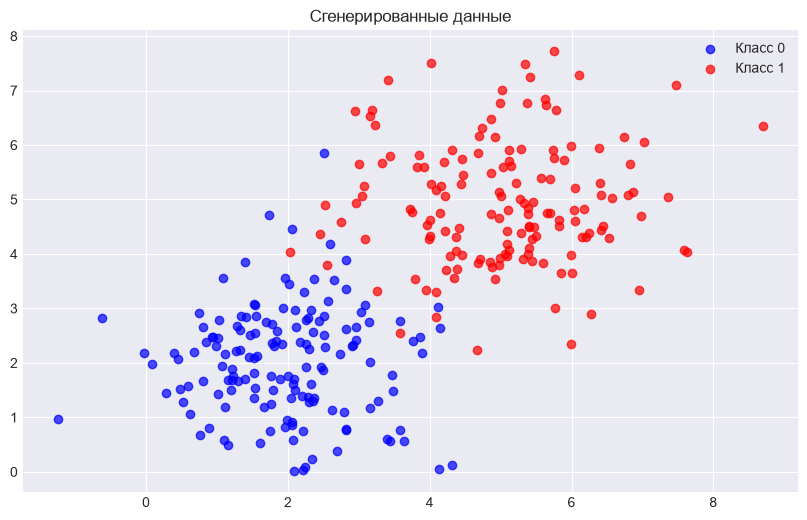

In [8]:
# Класс 0
n_pts = 150
X_0 = np.random.normal(loc=[2, 2], scale=1.0, size=(n_pts, 2))
y_0 = np.zeros(n_pts)

# Класс 1
X_1 = np.random.normal(loc=[5, 5], scale=1.2, size=(n_pts, 2))
y_1 = np.ones(n_pts)

# Объединяем и перемешиваем
X = np.vstack((X_0, X_1))
y = np.concatenate((y_0, y_1))

indices = np.arange(X.shape[0])
np.random.shuffle(indices)
X, y = X[indices], y[indices]

# Разделение на train и test
split_idx = int(0.8 * X.shape[0])
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

plt.scatter(X[y==0][:, 0], X[y==0][:, 1], color='blue', label='Класс 0', alpha=0.7)
plt.scatter(X[y==1][:, 0], X[y==1][:, 1], color='red', label='Класс 1', alpha=0.7)
plt.title("Сгенерированные данные")
plt.legend()
plt.show()

## 3. Обучение модели и оценка качества
Обучим модель на тренировочной выборке, построим график функции потерь и оценим метрики на тестовой выборке.

Метрики качества на тестовой выборке
Accuracy:  0.9667
Precision: 0.9259
Recall:    1.0000
F1-Score:  0.9615


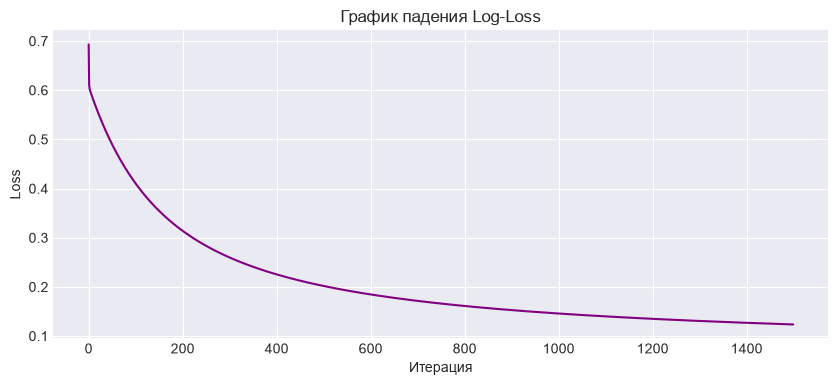

In [9]:
model = MyLogisticRegression(learning_rate=0.1, n_iters=1500)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Метрики качества на тестовой выборке")
print(f"Accuracy:  {MyLogisticRegression.accuracy(y_test, y_pred):.4f}")
print(f"Precision: {MyLogisticRegression.precision(y_test, y_pred):.4f}")
print(f"Recall:    {MyLogisticRegression.recall(y_test, y_pred):.4f}")
print(f"F1-Score:  {MyLogisticRegression.f1_score(y_test, y_pred):.4f}")

plt.figure(figsize=(10, 4))
plt.plot(model.loss_history, color='purple')
plt.title('График падения Log-Loss')
plt.xlabel('Итерация')
plt.ylabel('Loss')
plt.show()

## 4. Визуализация разделяющей гиперплоскости
Построим границу принятия решений, где вероятность принадлежности к классу $1$ равна $0.5$.

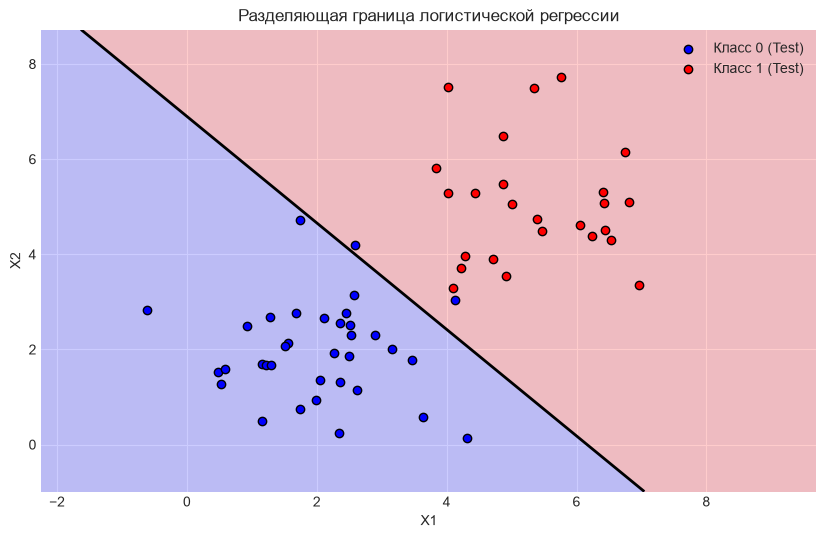

In [10]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

grid_X = np.c_[xx.ravel(), yy.ravel()]
probs = model.predict_proba(grid_X).reshape(xx.shape)

plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, probs, levels=[0, 0.5, 1], alpha=0.2, colors=['blue', 'red'])
plt.contour(xx, yy, probs, levels=[0.5], colors='black', linewidths=2)

plt.scatter(X_test[y_test==0][:, 0], X_test[y_test==0][:, 1], color='blue', edgecolor='k', label='Класс 0 (Test)')
plt.scatter(X_test[y_test==1][:, 0], X_test[y_test==1][:, 1], color='red', edgecolor='k', label='Класс 1 (Test)')

plt.title('Разделяющая граница логистической регрессии')
plt.xlabel('X1')
plt.ylabel('X2')
plt.legend()
plt.show()